**AICE Associate <font color=red>모의고사 (문제)</font>** — AICE_Asso_050_초급_분류_상담센터고객만족분석

### **상담센터 고객 만족 분석 — <span style="color:darkgreen">상위 부서 이관 여부</span> 예측 모델 개발**
---

- 도메인 : 상담센터 고객 만족 분석
- 목  표 : 상담의 상위 부서 이관 여부를 예측하는 인공지능모델 개발
- 품질관리팀은 접수·응대 데이터로 불만족 상담을 미리 가려내 코칭하려 한다.
- 상담 만족도 하락으로 새싹고객의 위탁 재계약에 부정적 영향이 우려된다.
- 상담 건 1,060건 안팎의 이력 데이터를 활용할 수 있다.
- 모델이 상위 부서 이관 여부를 신뢰할 만한 수준으로 예측하면 현업의 대응 비용을 줄일 수 있을 것으로 기대한다.

---

#### **[유의사항]**
- 각 문항의 답은 `# (번호) 정답을 입력하세요` 셀의 `정답01` ~ `정답14` 변수에 **값만** 입력합니다. 채점은 이 값으로만 합니다.
- 숫자는 문항이 안내한 자릿수로 반올림해 입력하고, 글자는 따옴표로 감싸 입력하세요(예: `정답01 = 'pandas'`).
- 답을 구하는 코드는 문항의 작업 셀에 작성하고 실행하세요. 제공된 문항 셀을 삭제하지 마세요.
- 문항에 변수명이 제시된 경우 반드시 해당 변수명을 사용하세요. 앞 문항의 결과를 뒤 문항이 이어서 사용합니다.
- 막히면 문항 아래 접혀 있는 **힌트 1·2·3단계**를 순서대로 펼쳐 보세요. 단계가 올라갈수록 정답에 가까워집니다.
- 모든 데이터는 가상으로 생성한 합성데이터이며, 실제 AICE 시험문항의 원문을 복제하지 않았습니다.

#### **[학습 정보]**
- 학습 목표 : 새싹고객의 데이터로 상담의 상위 부서 이관 여부를 예측하는 AI 모델을 만들며 데이터 분석·전처리·모델링 전 과정을 수행할 수 있다
- AICE 역량 : 데이터 분석(DA1 분석 환경 구성, DA2 데이터 불러오기·구조 파악, DA4 데이터 시각화) / 데이터 전처리(DP1 이상치 처리, DP2 결측치 처리, DP3 인코딩·변수 변환, DP4 데이터 분할, DP5 스케일링) / AI 모델링(AM1 머신러닝 모델 학습·탐색, AM2 모델 해석, AM3 모델 성능 평가, AM4 딥러닝 모델 구성·학습, AM5 딥러닝 학습 결과 분석)
- 기술 스택 : pandas(import pandas as pd, read_csv, head, quantile, reset_index, drop, dropna, sum, isnull, loc, value_counts, isin, get_dummies, info, DataFrame, sort_values, columns, shape) · seaborn(countplot, histplot, jointplot, barplot) · matplotlib(subplots, show, plot, title, xlabel, ylabel, legend) · scikit-learn(train_test_split, MinMaxScaler, fit_transform, transform, KNeighborsClassifier, fit, RandomForestClassifier, feature_importances_, predict, recall_score, LabelEncoder) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit, Dense, history)
- 난이도 : 초급 (설계 난이도 점수 2.76 / 5)
- 예상 소요 시간 : 약 122분 (문항별 시간은 각 문항 제목 아래)
- 관련 도메인 : 상담센터 고객 만족 분석 (고객 서비스)

**[ 데이터 컬럼 설명 (데이터 파일명: data.csv) ]**

- serialNo              : 일련번호
- waitSec               : 대기 시간(초)
- talkMin               : 통화 시간(분)
- transferCnt           : 상담 이관 횟수
- repeatCall            : 동일 이슈 재문의 횟수
- agentExpM             : 상담사 경력(개월)
- scriptScore           : 응대 스크립트 준수율(%)
- queueLen              : 접수 시 대기열 길이
- issueType             : 문의 유형
- agentTier             : 상담사 등급 (복수 값은 | 로 결합되어 있음)
- timeSlot              : 접수 시간대
- escalate              : 상위 부서 이관 여부 (Resolved, Escalated)

## <font color=blue>**<데이터 분석 (20점)>**</font>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요.**

In [1]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

### **1. 분석에 쓸 pandas 라이브러리를 준비하려 합니다. 아래 가이드의 별칭(alias)으로 불러오세요.**

<sub>학습 목표: 분석에 필요한 파이썬 라이브러리를 관용 별칭으로 불러올 수 있다 | 역량: DA1 분석 환경 구성 | 기술: pandas(import pandas as pd) | 난이도: 기초 | 예상 시간: 3분</sub>

- 불러올 라이브러리 : `pandas`
- 붙일 별칭 : `pd`
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답01]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답01]** 의 값만 답안 셀에 `정답01 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

In [2]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

import pandas as pd

In [3]:
# (1) 정답을 입력하세요 — `정답01` 에 값만 넣고 실행하세요

정답01 = 'pandas'

<details><summary>힌트 1단계 (접근 방향) - 1번 문항</summary>

`import 라이브러리 as 별칭` 문법으로 라이브러리를 불러옵니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 1번 문항</summary>

사용할 도구: `import ... as ...`. 정답은 6글자이고 첫 글자는 `p` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 1번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import pan___ as pd

정답01 = 'pan___'   # 빈칸에 넣은 단어
```

</details>

### **2. 분석의 첫 단계로 제공된 데이터 파일을 불러오려 합니다. pandas로 데이터 파일을 읽어온 뒤, 데이터프레임 변수명 df_raw 에 할당하고 첫 3개 행을 출력하십시오.**

<sub>학습 목표: CSV 파일을 데이터프레임으로 읽고 행·열 구성을 확인할 수 있다 | 역량: DA2 데이터 불러오기·구조 파악 | 기술: pandas(read_csv, head) | 난이도: 기초 | 예상 시간: 4분</sub>

- 앞 문항 결과 사용 : 1번 `pd`
- 다음 지침에 따라 코드를 작성하고 실행하세요
    - 파일은 이 노트북과 같은 폴더에 있습니다
    - 데이터프레임 변수명 : df_raw / 데이터 파일명 : data.csv
- **[정답02]** 읽어 온 데이터의 **열(column)의 개수** 를 작성하세요
- 답안 : **[정답02]** 의 값만 답안 셀에 `정답02 = 값` 형태로 입력하세요
- 배점 : 5점

---

In [4]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

df_raw.shape[1]


12

In [5]:
# (2) 정답을 입력하세요 — `정답02` 에 값만 넣고 실행하세요

정답02 = 12

<details><summary>힌트 1단계 (접근 방향) - 2번 문항</summary>

파일 형식(csv/json/구분자)에 맞는 pandas 읽기 함수와 옵션을 고르세요. 읽어 온 df_raw 로 열(column)의 개수를 직접 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 2번 문항</summary>

사용할 도구: `pd.read_csv`, `shape`, `select_dtypes`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 2번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_raw = pd.read_csv('./data.csv')
df_raw.head(3)

# [정답02] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
print(df_raw.shape[__])
```

</details>

### **3. 시각화를 통해 접수 시간대(timeSlot)와(과) 대기 시간(초)(waitSec)의 분포와 관계를 파악하려 합니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(countplot, histplot) · matplotlib(subplots, show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 접수 시간대(timeSlot)의 분포를 보여주는 countplot와 대기 시간(초)(waitSec)의 분포를 문의 유형(issueType) 별로 보여주는 histplot를 subplots를 활용해 가로 방향으로 나란히 그립니다
- 두 그래프의 제목을 각각 'Group Plot'와 'Right Chart'로 설정합니다
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답03]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답03]** 의 값만 답안 셀에 `정답03 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51200 (\N{HANGUL SYLLABLE JEO}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 45377 (\N{HANGUL SYLLABLE NYEOG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51204 (\N{HANGUL SYLLABLE JEON}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/

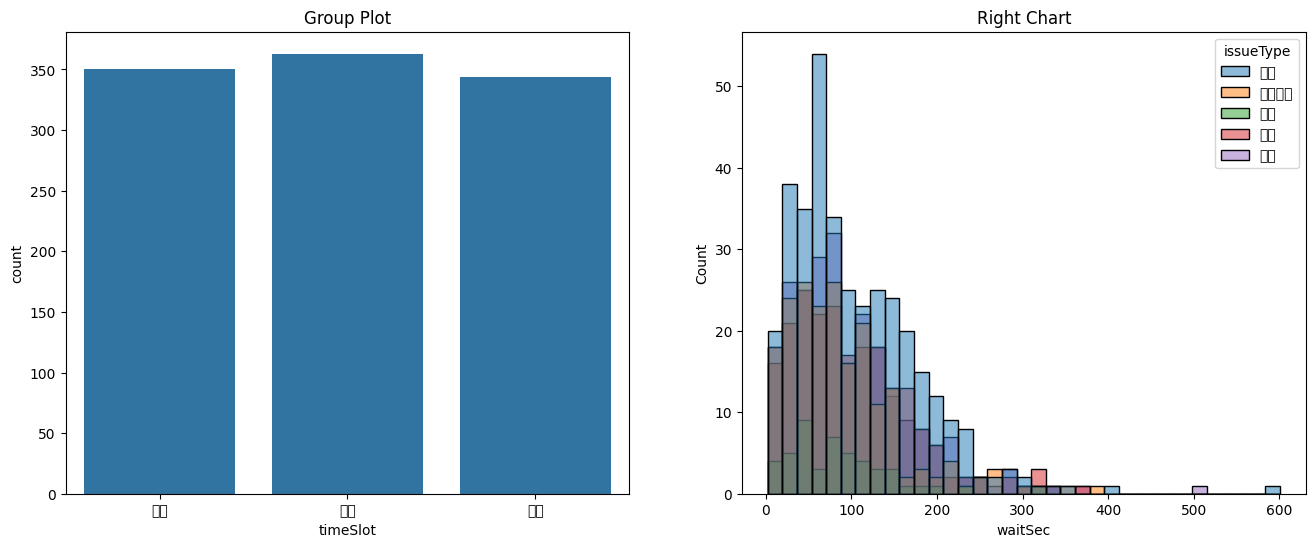

In [6]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.countplot(data=df_raw, x='timeSlot', ax=axes[0])
sns.histplot(data=df_raw, x='waitSec', hue='issueType', ax=axes[1])

axes[0].set_title('Group Plot')
axes[1].set_title('Right Chart')

plt.show()

In [7]:
# (3) 정답을 입력하세요 — `정답03` 에 값만 넣고 실행하세요

정답03 = 'histplot'

<details><summary>힌트 1단계 (접근 방향) - 3번 문항</summary>

빈칸의 정답을 먼저 채워 코드 전체를 실행하세요. 수치 분포를 구간별 막대(히스토그램)로 보여주는 seaborn 그래프입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 3번 문항</summary>

사용할 도구: `plt.subplots`, `sns.countplot`, `sns.histplot`. 정답은 8글자이고 첫 글자는 `h` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 3번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(16, 6))

sns.countplot(data=df_raw, x='timeSlot', ax=axes[0])
sns.hist____(data=df_raw, x='waitSec', hue='issueType', ax=axes[1])

axes[0].set_title('Group Plot')
axes[1].set_title('Right Chart')

plt.show()

정답03 = 'hist____'   # 빈칸에 넣은 단어
```

</details>

### **4. 그래프를 통해 상담 이관 횟수(transferCnt)와(과) 응대 스크립트 준수율(%)(scriptScore)의 분포와 관계를 함께 확인할 계획입니다.**

<sub>학습 목표: 그래프로 변수의 분포와 관계를 시각화할 수 있다 | 역량: DA4 데이터 시각화 | 기술: seaborn(jointplot) · matplotlib(show) | 난이도: 보통 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- seaborn 의 jointplot 으로 시각화하세요
- X축: transferCnt, Y축: scriptScore
- 그래프 종류(kind)는 'reg' 로 할당하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답04]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답04]** 의 값만 답안 셀에 `정답04 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 5점

---

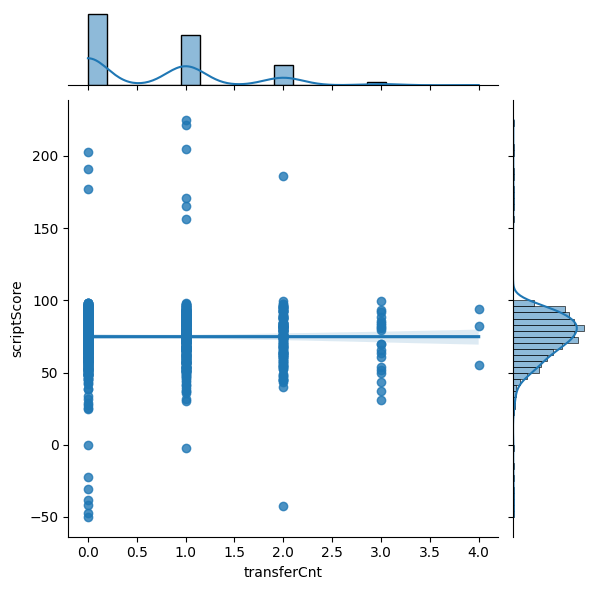

In [8]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

sns.jointplot(data=df_raw, x='transferCnt', y='scriptScore', kind='reg')
plt.show()

In [9]:
# (4) 정답을 입력하세요 — `정답04` 에 값만 넣고 실행하세요

정답04 = 'jointplot'

<details><summary>힌트 1단계 (접근 방향) - 4번 문항</summary>

두 변수의 관계와 각각의 분포를 한 그림에 그리는 그래프입니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 4번 문항</summary>

사용할 도구: `sns.jointplot`. 정답은 9글자이고 첫 글자는 `j` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 4번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import seaborn as sns
import matplotlib.pyplot as plt

sns.joint____(data=df_raw, x='transferCnt', y='scriptScore', kind='reg')
plt.show()

정답04 = 'joint____'   # 빈칸에 넣은 단어
```

</details>

## <font color=blue>**<데이터 전처리 (30점)>**</font>

### **5. 응대 스크립트 준수율(%)(scriptScore) 컬럼의 이상치를 IQR 기준으로 제거하려 합니다. 제시된 가이드에 맞춰 처리하세요.**

<sub>학습 목표: 사분위 범위(IQR) 등의 기준으로 이상치를 찾아 처리할 수 있다 | 역량: DP1 이상치 처리 | 기술: pandas(quantile, reset_index, drop) | 난이도: 보통 | 예상 시간: 8분</sub>

- 앞 문항 결과 사용 : 2번 `df_raw`
- 대상 데이터프레임 : df_raw
- 사분위수(Q1, Q3)와 IQR 을 계산하세요
- lower_fence = Q1 - 1.5 x IQR, upper_fence = Q3 + 1.5 x IQR 로 정의하세요
- scriptScore 이(가) 두 fence 밖에 있는 행을 삭제하세요
- 식별자 컬럼 serialNo 도 삭제하고 인덱스를 0부터 다시 매겨 df_clean 에 보관하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답05]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답05]** 의 값만 답안 셀에 `정답05 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [10]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

q1 = df_raw['scriptScore'].quantile(0.25)
q3 = df_raw['scriptScore'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['scriptScore'] > upper_fence) | (df_raw['scriptScore'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['serialNo']).reset_index(drop=True)

In [11]:
# (5) 정답을 입력하세요 — `정답05` 에 값만 넣고 실행하세요

정답05 = 'quantile'

<details><summary>힌트 1단계 (접근 방향) - 5번 문항</summary>

분위수로 fence 를 계산하고, 범위 밖 여부를 불리언으로 만든 뒤 반대로 선택합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 5번 문항</summary>

사용할 도구: `quantile`, `drop`, `reset_index`. 정답은 8글자이고 첫 글자는 `q` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 5번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
q1 = df_raw['scriptScore'].quan____(0.25)
q3 = df_raw['scriptScore'].quantile(0.75)
iqr = q3 - q1

lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr

is_out = (df_raw['scriptScore'] > upper_fence) | (df_raw['scriptScore'] < lower_fence)
df_clean = df_raw[~is_out].drop(columns=['serialNo']).reset_index(drop=True)

정답05 = 'quan____'   # 빈칸에 넣은 단어
```

</details>

### **6. 아래 안내대로 결측치를 처리하고 검증하는데 에러가 나고 있습니다. 코드의 오류를 정정하세요.**

<sub>학습 목표: 결측치를 확인하고 삭제하거나 대체할 수 있다 | 역량: DP2 결측치 처리 | 기술: pandas(dropna, sum, isnull) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 5번 `df_clean`
- 코드의 오류를 수정하세요
    - 대상 데이터프레임 : df_clean
    - 결측치 개수를 확인한 뒤, 결측치가 있는 행을 모두 삭제해 df_filled 에 보관하세요
    - 처리 후 결측치가 사라졌는지 확인하세요
- **[정답06]** 처리 전 df_clean 의 결측치는 총 몇 개로 나타나나요?
- 답안 : **[정답06]** 의 값만 답안 셀에 `정답06 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [12]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

print('결측치 처리 전\n', df_clean.isnull().sum())
df_filled = df_clean.dropna()
print('결측치 처리 후\n', df_filled.isnull().sum())

결측치 처리 전
 waitSec         0
talkMin         0
transferCnt    45
repeatCall     88
agentExpM       0
scriptScore     0
queueLen        0
issueType       0
agentTier       0
timeSlot        0
escalate        0
dtype: int64
결측치 처리 후
 waitSec        0
talkMin        0
transferCnt    0
repeatCall     0
agentExpM      0
scriptScore    0
queueLen       0
issueType      0
agentTier      0
timeSlot       0
escalate       0
dtype: int64


In [13]:
# (6) 정답을 입력하세요 — `정답06` 에 값만 넣고 실행하세요

정답06 = 133

<details><summary>힌트 1단계 (접근 방향) - 6번 문항</summary>

결측치 확인 -> 삭제 -> 재확인 순서로 코드를 읽어 보세요. 결측치 처리 전 데이터프레임의 결측치 합계를 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 6번 문항</summary>

사용할 도구: `isnull`, `sum`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 6번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
print('결측치 처리 전\n', df_clean.isnull().sum())
df_filled = df_clean.dropna()
print('결측치 처리 후\n', df_filled.isnull().sum())

# [정답06] 실행한 결과를 입력하세요
df_clean.isnull().sum().sum()
```

</details>

### **7. 원-핫 인코딩(One-Hot Encoding)은 범주형 데이터를 1과 0의 이진형 벡터로 변환하는 방법입니다. 제시된 가이드에 맞춰 범주형 데이터를 처리하고 인코딩하세요.**

<sub>학습 목표: 범주형 변수를 인코딩하고 변수를 정리·변환할 수 있다 | 역량: DP3 인코딩·변수 변환 | 기술: pandas(loc, value_counts, isin, get_dummies) | 난이도: 어려움 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 6번 `df_filled`
- 아래 가이드에 따라 데이터를 처리하는 코드를 작성하고 실행하세요
    - 대상 데이터프레임 : df_filled
    - 상담사 등급(agentTier) 의 값 '신입|일반', '신입|전문' 을(를) '신입' 으로 치환하세요
    - 상담사 등급(agentTier) 의 값 '일반|신입', '일반|전문' 을(를) '일반' 으로 치환하세요
    - 상담사 등급(agentTier) 의 값 '전문|신입', '전문|일반' 을(를) '전문' 으로 치환하세요
    - 치환 후 범주별 개수를 출력하세요
- 남은 문자열 컬럼을 모두 원-핫 인코딩(get_dummies, drop_first=True)하는데 에러가 나고 있습니다. 코드의 오류를 정정하고 결과를 df_final 에 담으세요
- **[정답07]** 인코딩 후 df_final 의 **전체 컬럼 개수**는 몇 개로 나타나나요?
- 답안 : **[정답07]** 의 값만 답안 셀에 `정답07 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [14]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요 (채점하지 않음)

df_filled.loc[df_filled['agentTier'].isin(['신입|일반', '신입|전문']), 'agentTier'] = '신입'
df_filled.loc[df_filled['agentTier'].isin(['일반|신입', '일반|전문']), 'agentTier'] = '일반'
df_filled.loc[df_filled['agentTier'].isin(['전문|신입', '전문|일반']), 'agentTier'] = '전문'

print(df_filled['agentTier'].value_counts())

agentTier
일반    401
전문    373
신입    126
Name: count, dtype: int64


In [15]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

df_final = pd.get_dummies(data=df_filled, columns=['issueType', 'agentTier', 'timeSlot'], drop_first=True)
df_final.info()

<class 'pandas.core.frame.DataFrame'>
Index: 900 entries, 0 to 1025
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   waitSec         900 non-null    float64
 1   talkMin         900 non-null    float64
 2   transferCnt     900 non-null    float64
 3   repeatCall      900 non-null    float64
 4   agentExpM       900 non-null    float64
 5   scriptScore     900 non-null    float64
 6   queueLen        900 non-null    float64
 7   escalate        900 non-null    object 
 8   issueType_상품문의  900 non-null    bool   
 9   issueType_요금    900 non-null    bool   
 10  issueType_장애    900 non-null    bool   
 11  issueType_해지    900 non-null    bool   
 12  agentTier_일반    900 non-null    bool   
 13  agentTier_전문    900 non-null    bool   
 14  timeSlot_오후     900 non-null    bool   
 15  timeSlot_저녁     900 non-null    bool   
dtypes: bool(8), float64(7), object(1)
memory usage: 70.3+ KB


In [16]:
# (7) 정답을 입력하세요 — `정답07` 에 값만 넣고 실행하세요

정답07 = 16

<details><summary>힌트 1단계 (접근 방향) - 7번 문항</summary>

빈칸을 채워 치환 코드를 완성해 실행하세요. 값이 주어진 목록에 포함되는지 검사하는 메서드입니다. 인코딩이 끝난 데이터프레임의 컬럼 개수를 확인하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 7번 문항</summary>

사용할 도구: `isin`, `loc`, `value_counts`, `shape`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 7번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd

df_filled.loc[df_filled['agentTier'].isin(['신입|일반', '신입|전문']), 'agentTier'] = '신입'
df_filled.loc[df_filled['agentTier'].isin(['일반|신입', '일반|전문']), 'agentTier'] = '일반'
df_filled.loc[df_filled['agentTier'].isin(['전문|신입', '전문|일반']), 'agentTier'] = '전문'

print(df_filled['agentTier'].value_counts())

df_final = pd.get_dummies(data=df_filled, columns=['issueType', 'agentTier', 'timeSlot'], drop_first=True)
df_final.info()

# [정답07] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
df_final.shape[__]
```

</details>

### **8. 훈련과 검증 데이터셋을 분리하고, 분리된 데이터의 크기를 확인하려 합니다.**

<sub>학습 목표: 피처와 레이블을 나누고 훈련·검증 데이터로 분할할 수 있다 | 역량: DP4 데이터 분할 | 기술: pandas(drop) · scikit-learn(train_test_split) | 난이도: 쉬움 | 예상 시간: 6분</sub>

- 앞 문항 결과 사용 : 7번 `df_final`
- 대상 데이터프레임 : df_final
- 상위 부서 이관 여부(escalate) 컬럼을 레이블값 y 로, 나머지 컬럼을 피처값 X 로 지정하세요
- 훈련과 검증 데이터셋의 클래스 비율을 동일하게 하는 옵션(stratify)을 설정하세요
- 변수명 : X_train, X_valid, y_train, y_valid (훈련 피처/검증 피처/훈련 레이블/검증 레이블)
- train_test_split 함수(scikit-learn)로 나누세요
- 훈련과 검증 데이터셋 분리 — 훈련 : 검증 = 70:30 (test_size=0.3)
- 난수 시드(random_state)는 11 로 설정하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답08]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답08]** 의 값만 답안 셀에 `정답08 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 6점

---

In [17]:
# (코드 셀) 코드의 빈칸(____)을 채우고 실행하세요

from sklearn.model_selection import train_test_split

X = df_final.drop('escalate', axis=1)
y = df_final['escalate']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=11, stratify=y)

In [18]:
# (8) 정답을 입력하세요 — `정답08` 에 값만 넣고 실행하세요

정답08 = 'test_size'

<details><summary>힌트 1단계 (접근 방향) - 8번 문항</summary>

피처와 레이블을 나눈 뒤, 훈련/검증으로 무작위 분할합니다. 코드의 흐름(앞뒤 변수와 인자)을 보고 이 자리에 들어갈 함수·옵션 이름을 떠올려 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 8번 문항</summary>

사용할 도구: `train_test_split`, `drop`. 정답은 9글자이고 첫 글자는 `t` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 8번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.model_selection import train_test_split

X = df_final.drop('escalate', axis=1)
y = df_final['escalate']

X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_____=0.3, random_state=11, stratify=y)

정답08 = 'test_____'   # 빈칸에 넣은 단어
```

</details>

### **9. 스케일링을 통해 변수들의 단위(범위) 차이가 모델에 미치는 영향을 줄이려 합니다. (최솟값 0~최댓값 1 정규화)**

<sub>학습 목표: 훈련 데이터로 스케일러를 학습해 검증 데이터에 같은 기준을 적용할 수 있다 | 역량: DP5 스케일링 | 기술: scikit-learn(MinMaxScaler, fit_transform, transform) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `X_train`, `X_valid`
- 아래 안내대로 스케일링 처리하는데 에러가 나고 있습니다. 코드의 오류를 수정하세요
    - sklearn.preprocessing 에서 MinMaxScaler 를 import 하세요
    - MinMaxScaler 를 sc 변수에 할당하세요
    - 훈련 데이터(X_train)에 대해 스케일러를 학습시키고 변환을 적용해 X_train 에 다시 담으세요
    - 검증 데이터(X_valid)에는 **학습된 기준을 그대로** 적용(변환만)해 X_valid 에 보관하세요
- **[정답09]** MinMaxScaler 적용 후 검증 데이터(X_valid)의 **최솟값**을 소수 둘째 자리까지 입력하세요
- 답안 : **[정답09]** 의 값만 답안 셀에 `정답09 = 값` 형태로 입력하세요
- 배점 : 6점

---

In [20]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

print(X_valid.min())

-0.019138755980861347


In [21]:
# (9) 정답을 입력하세요 — `정답09` 에 값만 넣고 실행하세요

정답09 = -0.02

<details><summary>힌트 1단계 (접근 방향) - 9번 문항</summary>

훈련 데이터로 fit, 검증 데이터는 transform 만 하는 규칙을 떠올리세요. 변환된 검증 데이터 전체에서 최솟값을 구하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 9번 문항</summary>

사용할 도구: `np.min`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 9번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import numpy as np

from sklearn.preprocessing import MinMaxScaler

sc = MinMaxScaler()
X_train = sc.fit_transform(X_train)
X_valid = sc.transform(X_valid)

# [정답09] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(np.min(X_valid), __)
```

</details>

## <font color=blue>**<AI 모델링 (50점)>**</font>

### **10. 상위 부서 이관 여부(escalate)을(를) 예측하는 머신러닝 모델을 만들려고 합니다. KNN와(과) RandomForest는 각각 서로 다른 방식으로 예측하는 모델입니다.**

<sub>학습 목표: 머신러닝 모델에 하이퍼파라미터를 지정해 학습하고 결과를 확인할 수 있다 | 역량: AM1 머신러닝 모델 학습·탐색 | 기술: scikit-learn(KNeighborsClassifier, fit, RandomForestClassifier) | 난이도: 쉬움 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 8번 `y_train` · 9번 `X_train`
- KNN 모델을 아래와 같이 만들어 `knn` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_neighbors=3, weights='uniform'
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- RandomForest 모델을 아래와 같이 만들어 `rf` 변수에 저장하고 학습시키세요
    - 하이퍼파라미터 : n_estimators=50, max_depth=8
    - 난수 시드(random_state) : 2024
    - 앞서 분리한 훈련데이터셋(X_train, y_train)으로 fit 함수를 사용해 학습시키세요
- **[정답10]** 학습된 `knn`(KNN) 의 **훈련 데이터** 점수 `knn.score(X_train, y_train)` (정확도(accuracy))를 소수점 셋째 자리까지 작성하세요
- 답안 : **[정답10]** 의 값만 답안 셀에 `정답10 = 값` 형태로 입력하세요
- 배점 : 10점

---

In [25]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

knn = KNeighborsClassifier(n_neighbors=3, weights='uniform')
knn.fit(X_train, y_train)

rf = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=2024)
rf.fit(X_train, y_train)

round(knn.score(X_train, y_train), 3)


0.832

In [ ]:
# 작업 셀 : 가이드에 따라 코드를 작성하고 실행하세요 (채점하지 않음)



In [26]:
# (10) 정답을 입력하세요 — `정답10` 에 값만 넣고 실행하세요

정답10 = 0.832

<details><summary>힌트 1단계 (접근 방향) - 10번 문항</summary>

모델 객체를 하이퍼파라미터와 함께 만들고 훈련 데이터로 fit 합니다. 학습된 모델의 score 메서드에 훈련 데이터를 넣고 반올림하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 10번 문항</summary>

사용할 도구: `KNeighborsClassifier`, `fit`, `RandomForestClassifier`, `score`, `round`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 10번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=3, weights='uniform')
knn.fit(X_train, y_train)

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=2024)
rf.fit(X_train, y_train)

# [정답10] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
round(knn.score(X_train, y_train), __)
```

</details>

### **11. 모델의 해석력과 개선 방향을 이해하기 위해 RandomForest 모델의 변수중요도를 파악하려고 합니다.**

<sub>학습 목표: 변수 중요도·계수로 모델이 어떤 변수에 의존하는지 해석할 수 있다 | 역량: AM2 모델 해석 | 기술: pandas(DataFrame, sort_values, columns) · seaborn(barplot) · matplotlib(show) · scikit-learn(feature_importances_) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 1번 `pd` · 8번 `X` · 10번 `rf`
- 아래 안내대로 모델의 변수중요도를 파악하는데 에러가 나고 있습니다. 코드의 오류를 바로잡으세요
    - 앞서 학습시킨 RandomForest 모델 `rf` 를 사용하세요
    - 변수중요도 점수와 변수 이름(X.columns)을 매핑하여 DataFrame(fi)을 만드세요
    - 변수중요도 점수를 기준으로 내림차순 정렬하고 Top 10 개만 선정하세요
    - 변수중요도 점수를 막대 그래프(seaborn barplot)로 시각화하세요
- **[정답11]** 출력된 그래프에서 **가장 높은 중요도**를 보이는 변수명을 쓰세요
- 답안 : **[정답11]** 의 값만 답안 셀에 `정답11 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 51068 (\N{HANGUL SYLLABLE IL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 48152 (\N{HANGUL SYLLABLE BAN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 50724 (\N{HANGUL SYLLABLE O}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49345 (\N{HANGUL SYLLABLE SANG}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/loc

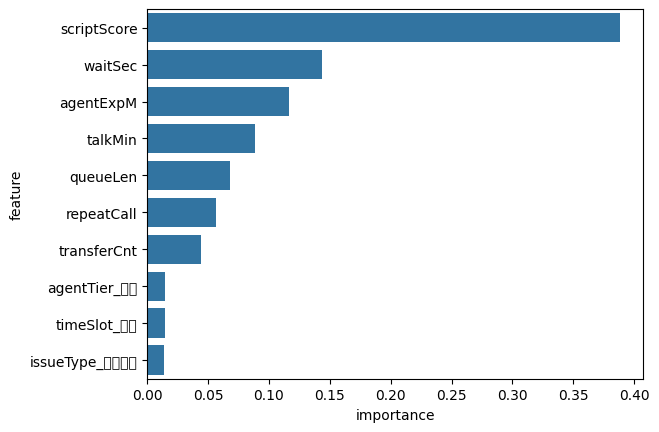

In [28]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

In [29]:
# (11) 정답을 입력하세요 — `정답11` 에 값만 넣고 실행하세요

정답11 = 'scriptScore'

<details><summary>힌트 1단계 (접근 방향) - 11번 문항</summary>

변수 중요도를 DataFrame 으로 만들고 정렬해 그리는 흐름을 점검하세요. fi 의 첫 번째 행(가장 큰 중요도)의 feature 값을 보세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 11번 문항</summary>

사용할 도구: `sort_values`, `iloc`.

</details>

<details><summary>힌트 3단계 (전체 코드) - 11번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

fi = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi)
plt.show()

# [정답11] `__`·`____` 자리를 채워 실행한 결과를 입력하세요
fi['____'].iloc[__]
```

</details>

### **12. 앞서 학습시킨 KNN와(과) RandomForest 모델의 성능을 평가하려고 합니다.**

<sub>학습 목표: 평가 지표로 두 모델의 성능을 비교할 수 있다 | 역량: AM3 모델 성능 평가 | 기술: scikit-learn(predict, recall_score) | 난이도: 보통 | 예상 시간: 12분</sub>

- 앞 문항 결과 사용 : 8번 `y_valid` · 9번 `X_valid` · 10번 `knn`, `rf`
- 다음 지침에 따라 각 모델의 Recall(macro) 를 산출하려는데 실행 중 예외가 발생합니다. 코드의 오류를 수정하세요
    - 앞서 학습시킨 knn 와 rf 모델을 사용하세요
    - 성능 평가는 **검증데이터셋(X_valid, y_valid)** 을 활용하세요
    - 두 모델의 Recall(macro) 값을 각각 knn_score, rf_score 변수에 저장하고 출력하세요
- **[정답12]** 두 모델의 Recall(macro) 결과를 비교했을 때, 성능이 **더 우수한** 모델은 무엇인가요? (KNN / RandomForest 중 하나)
- 답안 : **[정답12]** 의 값만 답안 셀에 `정답12 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [32]:
# 작업 셀 : 아래 코드의 오류를 정정하고 실행하세요 (채점하지 않음)

from sklearn.metrics import recall_score

y_pred_knn = knn.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

knn_score = recall_score(y_pred_knn, y_valid,average='macro')
rf_score = recall_score(y_valid, y_pred_rf, average='macro')
print(knn_score, rf_score)

0.6993657505285412 0.7524709926944564


In [33]:
# (12) 정답을 입력하세요 — `정답12` 에 값만 넣고 실행하세요

정답12 = 'RandomForest'

<details><summary>힌트 1단계 (접근 방향) - 12번 문항</summary>

Recall(macro) 를 계산하는 흐름(예측 -> 지표 함수)을 점검하세요. 값이 클수록 우수한 지표입니다. 두 점수를 비교하세요.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 12번 문항</summary>

가이드에 언급된 함수를 확인하세요.

</details>

<details><summary>힌트 3단계 (전체 코드) - 12번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 코드를 그대로 실행해 마지막 줄의 결과를 정답으로 입력하세요.
```python
from sklearn.metrics import recall_score

y_pred_knn = knn.predict(X_valid)
y_pred_rf = rf.predict(X_valid)

knn_score = recall_score(y_valid, y_pred_knn, average='macro')
rf_score = recall_score(y_valid, y_pred_rf, average='macro')
print(knn_score, rf_score)

# [정답12] 실행한 결과를 입력하세요
print(knn_score, rf_score)
```

</details>

> **<span style="color:red">다음 문항을 풀기 전에 </span>아래 코드를 실행하세요. (tensorflow 필요)**

In [34]:
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model, load_model
from tensorflow.keras.layers import Input, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam, RMSprop, Nadam, SGD
from tensorflow.keras.regularizers import l2
from tensorflow.keras.utils import to_categorical

tf.random.set_seed(100)

### **13. 상위 부서 이관 여부(escalate)을(를) 예측하는 딥러닝 모델을 만들려고 합니다. 아래 가이드를 참고해서 모델링하고 학습을 수행하십시오.**

<sub>학습 목표: 주어진 구조대로 Keras 딥러닝 모델을 구성하고 학습할 수 있다 | 역량: AM4 딥러닝 모델 구성·학습 | 기술: pandas(shape) · scikit-learn(LabelEncoder, fit_transform, transform) · TensorFlow(Keras)(Sequential, EarlyStopping, compile, fit) | 난이도: 보통 | 예상 시간: 13분</sub>

- 앞 문항 결과 사용 : 8번 `y_train`, `y_valid` · 9번 `X_train`, `X_valid`
- 딥러닝 프레임워크는 tensorflow 를 씁니다
- 은닉층은 Dense 레이어 2개(노드 수 [64, 32]), 활성화 함수는 'selu' 로 하세요
- EarlyStopping 으로 5번의 epoch 동안 val_loss 가 향상되지 않으면 훈련을 중지(restore_best_weights=True)하도록 설정하고 estop 변수에 담으세요
- Dropout 층은 사용하지 않습니다
- 출력층은 노드 1개, activation='sigmoid' 로 하세요
- optimizer 는 nadam, loss 는 binary_crossentropy, metrics 는 [accuracy] 로 지정해서 모델을 컴파일하세요
- batch_size 는 64, epochs 는 50 로 학습하고 학습정보는 history 변수에 저장하세요 (검증 데이터: X_valid, 검증 레이블), 학습 진행 로그는 출력하지 않도록 verbose=0 으로 설정하세요
- 가이드에 없는 인자는 추가하지 말고 기본값으로 두세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답13]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답13]** 의 값만 답안 셀에 `정답13 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

In [37]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(64, activation='selu', input_dim=X_train.shape[1]),
    Dense(32, activation='selu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='nadam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=50, batch_size=64,
                    validation_data=(X_valid, y_valid_enc),
                    verbose=0,
                    callbacks=cb_list)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [38]:
# (13) 정답을 입력하세요 — `정답13` 에 값만 넣고 실행하세요

정답13 = 'validation_data'

<details><summary>힌트 1단계 (접근 방향) - 13번 문항</summary>

가이드의 모델 구조·학습 조건을 코드의 각 줄과 대응시켜 보세요. fit 에서 검증용 데이터를 지정하는 인자입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 13번 문항</summary>

사용할 도구: `Sequential`, `Dense`, `Dropout`, `EarlyStopping`, `model.compile`, `model.fit`. 정답은 15글자이고 첫 글자는 `v` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 13번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_valid_enc = le.transform(y_valid)

model = Sequential([
    Dense(64, activation='selu', input_dim=X_train.shape[1]),
    Dense(32, activation='selu'),
    Dense(1, activation='sigmoid')
])

estop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
cb_list = [estop]

model.compile(optimizer='nadam', loss='binary_crossentropy', metrics=['accuracy'])

history = model.fit(X_train, y_train_enc,
                    epochs=50, batch_size=64,
                    validati_______=(X_valid, y_valid_enc),
                    verbose=0,
                    callbacks=cb_list)

정답13 = 'validati_______'   # 빈칸에 넣은 단어
```

</details>

### **14. 앞서 만든 딥러닝 모델의 일반화 성능을 평가하려고 합니다. matplotlib 라이브러리를 활용해서, 학습 Accuracy와(과) 검증 Accuracy의 변화를 그래프로 시각화하세요.**

<sub>학습 목표: 학습 기록으로 딥러닝 모델의 학습 과정과 성능을 분석할 수 있다 | 역량: AM5 딥러닝 학습 결과 분석 | 기술: matplotlib(plot, title, xlabel, ylabel) · TensorFlow(Keras)(history) | 난이도: 보통 | 예상 시간: 10분</sub>

- 앞 문항 결과 사용 : 13번 `history`
- 1개의 그래프에 학습 Accuracy 과 검증 Accuracy 2가지를 모두 표시하세요
- 두 선의 범례 : 'train', 'val'
- 그래프의 타이틀은 'Model Accuracy' 로, X축 이름은 'Epochs', Y축 이름은 'Accuracy' 로 표시하세요
- 아래 코드 셀(cell)의 코드를 실행해 결과를 확인하세요 — 빈칸(____)은 한 곳입니다
- **[정답14]** 아래 코드 셀의 빈칸(____)에 들어갈 내용(함수·인자·모듈 이름)을 입력하세요
- 답안 : **[정답14]** 의 값만 답안 셀에 `정답14 = 값` 형태로 입력하세요 (글자는 따옴표로 감싸기)
- 배점 : 10점

---

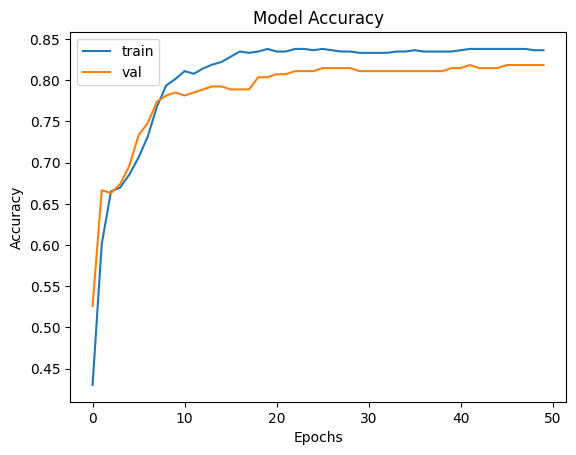

In [39]:
# (코드 셀) 코드의 빈칸을 채우고 실행하세요

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(['train', 'val'])
plt.show()

In [40]:
# (14) 정답을 입력하세요 — `정답14` 에 값만 넣고 실행하세요

정답14 = 'legend'

<details><summary>힌트 1단계 (접근 방향) - 14번 문항</summary>

빈칸을 채워 코드를 완성한 뒤 실행하세요. 범례를 표시하는 matplotlib 함수입니다.

</details>

<details><summary>힌트 2단계 (사용할 도구) - 14번 문항</summary>

사용할 도구: `plt.plot`, `plt.title`, `plt.xlabel`, `plt.ylabel`, `plt.legend`, `plt.show`. 정답은 6글자이고 첫 글자는 `l` 입니다.

</details>

<details><summary>힌트 3단계 (전체 코드) - 14번 문항</summary>

이 문항을 처음부터 끝까지 구현하는 코드입니다. 빈칸(____) 자리의 단어는 앞 글자만 보여 줍니다.
```python
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.leg___(['train', 'val'])
plt.show()

정답14 = 'leg___'   # 빈칸에 넣은 단어
```

</details>

### **모든 문항이 완료되었습니다. 수고하셨습니다.**
### 답안을 저장한 뒤 제출해 주시기 바랍니다.